In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

In [2]:
tx = pd.read_csv('Transction_cleaned.csv', keep_default_na=False, parse_dates=['Date'])
cust = pd.read_csv('customers_cleaned.csv', parse_dates=['Join_Date'])
prod = pd.read_csv('products_clean.csv')
stores = pd.read_csv('stores.csv')

In [3]:
print(tx.shape)
print(cust.shape)
print(prod.shape)
print(stores.shape)

(814929, 13)
(7000, 8)
(133, 9)
(25, 7)


In [4]:
display(tx.head())
display(cust.head())
display(prod.head())
stores.head()

,Line_ID,Transaction_ID,Customer_ID,Date,Product_ID,Product_Name,Category,Quantity,Unit_Price,Discount,Store,Payment_Method,Channel
0,1,T000001,C00112,2024-01-01,P117,Honey 250g,Sugar & Spices,1,70.0,0.0,Cairo - New Cairo,Credit Card,In-Store
1,2,T000001,C00112,2024-01-01,P114,Sugar 1kg,Sugar & Spices,1,30.0,0.0,Cairo - New Cairo,Credit Card,In-Store
2,3,T000001,C00112,2024-01-01,P125,Frozen Okra 400g,Frozen,4,28.0,0.0,Cairo - New Cairo,Credit Card,In-Store
3,4,T000001,C00112,2024-01-01,P062,Tea 100 bags,Beverages,3,55.0,0.0,Cairo - New Cairo,Credit Card,In-Store
4,5,T000001,C00112,2024-01-01,P085,Oranges 1kg,Fruits & Vegetables,2,24.0,0.0,Cairo - New Cairo,Credit Card,In-Store


,Customer_ID,City,Age_Group,Gender,Birth_Year,Join_Date,Loyalty_Member,Preferred_Payment
0,C00001,Cairo,35-44,Female,1974,2023-07-23,No,Cash
1,C00002,Port Said,45-54,Female,2001,2022-04-15,No,Credit Card
2,C00003,Cairo,35-44,Female,1976,2023-12-14,Yes,Credit Card
3,C00004,Cairo,45-54,Male,1978,2022-03-15,No,Cash
4,C00005,Cairo,25-34,Male,1984,2023-03-25,No,Mobile Wallet


,Product_ID,Product_Name,Category,Cost_Price,List_Price,Brand,Unit,Is_Perishable,Cost_Estimated
0,P001,Milk 1L,Dairy,24.0,32,FreshCo,1L,True,False
1,P002,Milk 500ml,Dairy,21.6,18,HomeChoice,500ml,True,False
2,P003,Yogurt 170g,Dairy,8.0,12,DailyBest,170g,True,False
3,P004,Greek Yogurt 150g,Dairy,14.0,20,DailyBest,150g,True,False
4,P005,White Cheese 500g,Dairy,58.0,75,Baraka,500g,True,False


,Store_ID,Store_Name,City,Area,Region,Size_Class,Opening_Date
0,S01,Cairo - Nasr City,Cairo,Nasr City,Greater Cairo,Large,2022-03-14
1,S02,Cairo - Maadi,Cairo,Maadi,Greater Cairo,Large,2018-11-19
2,S03,Cairo - Heliopolis,Cairo,Heliopolis,Greater Cairo,Medium,2018-02-17
3,S04,Cairo - New Cairo,Cairo,New Cairo,Greater Cairo,Large,2021-02-25
4,S05,Cairo - Shubra,Cairo,Shubra,Greater Cairo,Medium,2019-10-20


In [5]:
tx.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814929 entries, 0 to 814928
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Line_ID         814929 non-null  int64         
 1   Transaction_ID  814929 non-null  object        
 2   Customer_ID     814929 non-null  object        
 3   Date            814929 non-null  datetime64[ns]
 4   Product_ID      814929 non-null  object        
 5   Product_Name    814929 non-null  object        
 6   Category        814929 non-null  object        
 7   Quantity        814929 non-null  int64         
 8   Unit_Price      814929 non-null  float64       
 9   Discount        814929 non-null  float64       
 10  Store           814929 non-null  object        
 11  Payment_Method  814929 non-null  object        
 12  Channel         814929 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(8)
memory usage: 80.8+ MB


In [6]:
print(tx.isna().sum().sum())
print(cust.isna().sum().sum())
print(prod.isna().sum().sum())
print(stores.isna().sum().sum())

0
0
0
0


In [7]:
print(tx['Date'].min())
print(tx['Date'].max())
display(tx.drop(columns='Line_ID').duplicated().sum())
tx.duplicated(['Transaction_ID', 'Product_ID']).sum()

2024-01-01 00:00:00
2025-12-31 00:00:00


np.int64(0)

np.int64(2439)

In [8]:
display(tx[~tx['Customer_ID'].isin(cust['Customer_ID'])]['Customer_ID'].value_counts())
display(tx[~tx['Store'].isin(stores['Store_Name'])]['Store'].value_counts())
tx[~tx['Product_ID'].isin(prod['Product_ID'])].shape[0]

Customer_ID
Guest     15
C09582     1
C09823     1
Name: count, dtype: int64

Store
Unknown    2
Name: count, dtype: int64

0

In [9]:
inv_check = tx.groupby('Transaction_ID')[['Date', 'Customer_ID', 'Store', 'Channel', 'Payment_Method']].nunique()
display((inv_check > 1).any(axis=1).sum())
(prod['Cost_Price'] > prod['List_Price']).sum()

np.int64(0)

np.int64(3)

In [10]:
joined = tx.merge(cust[['Customer_ID', 'Join_Date']], on='Customer_ID')
before_join = joined[joined['Date'] < joined['Join_Date']]
print(len(before_join), 'of', len(joined))
before_join['Customer_ID'].nunique()

76476 of 814912


1900

In [11]:
df = tx.merge(prod[['Product_ID', 'Cost_Price', 'List_Price', 'Is_Perishable']], on='Product_ID')
df['Gross'] = df['Quantity'] * df['Unit_Price']
df['Discount_Amt'] = df['Gross'] * df['Discount']
df['Revenue'] = df['Gross'] - df['Discount_Amt']
df['Cost'] = df['Quantity'] * df['Cost_Price']
df['Profit'] = df['Revenue'] - df['Cost']

In [12]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['YM'] = df['Date'].dt.to_period('M')
df['Weekday'] = df['Date'].dt.day_name()

In [13]:
inv = df.groupby('Transaction_ID')[['Quantity', 'Revenue', 'Profit']].sum()
inv = inv.rename(columns={'Quantity': 'Items'})
inv['Lines'] = df.groupby('Transaction_ID').size()
inv['Unique_SKUs'] = df.groupby('Transaction_ID')['Product_ID'].nunique()
first = df.groupby('Transaction_ID')[['Date', 'Customer_ID', 'Store', 'Channel', 'Payment_Method']].first()
inv = inv.join(first).reset_index()
inv['YM'] = inv['Date'].dt.to_period('M')
inv['Weekday'] = inv['Date'].dt.day_name()

In [14]:
inv.head()

,Transaction_ID,Items,Revenue,Profit,Lines,Unique_SKUs,Date,Customer_ID,Store,Channel,Payment_Method,YM,Weekday
0,T000001,13,528.0,133.0,7,7,2024-01-01,C00112,Cairo - New Cairo,In-Store,Credit Card,2024-01,Monday
1,T000002,4,135.0,38.0,4,4,2024-01-01,C00167,Giza - Haram,In-Store,Credit Card,2024-01,Monday
2,T000003,7,263.4,63.4,4,4,2024-01-01,C00168,Assiut - Downtown,In-Store,Cash,2024-01,Monday
3,T000004,4,166.0,42.0,3,3,2024-01-01,C00173,Alexandria - Montaza,Delivery,Credit Card,2024-01,Monday
4,T000005,16,616.0,162.0,6,6,2024-01-01,C00258,Alexandria - Sidi Gaber,In-Store,Mobile Wallet,2024-01,Monday


In [15]:
print('revenue:', round(df['Revenue'].sum()))
print('profit:', round(df['Profit'].sum()))
print('margin:', round(df['Profit'].sum() / df['Revenue'].sum(), 3))
print('discount share:', round(df['Discount_Amt'].sum() / df['Gross'].sum(), 3))
print('invoices:', len(inv))
print('average invoice:', round(inv['Revenue'].mean()))
print('median invoice:', round(inv['Revenue'].median()))
print('lines per invoice:', round(inv['Lines'].mean(), 1))
print('items per invoice:', round(inv['Items'].mean(), 1))
print('customers:', cust.shape[0])
print('products:', df['Product_ID'].nunique())
print('stores:', stores.shape[0])

revenue: 75143797
profit: 20102542
margin: 0.268
discount share: 0.034
invoices: 136452
average invoice: 551
median invoice: 456
lines per invoice: 6.0
items per invoice: 12.7
customers: 7000
products: 133
stores: 25


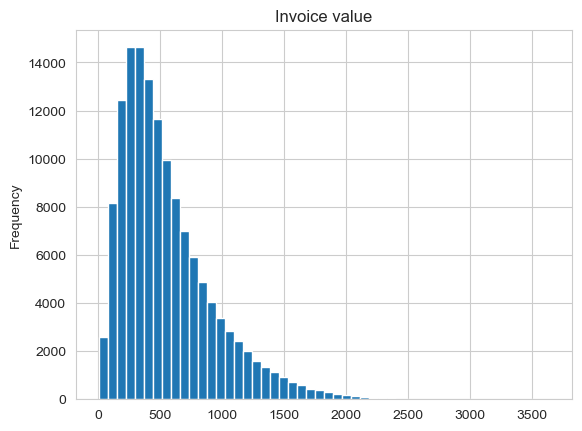

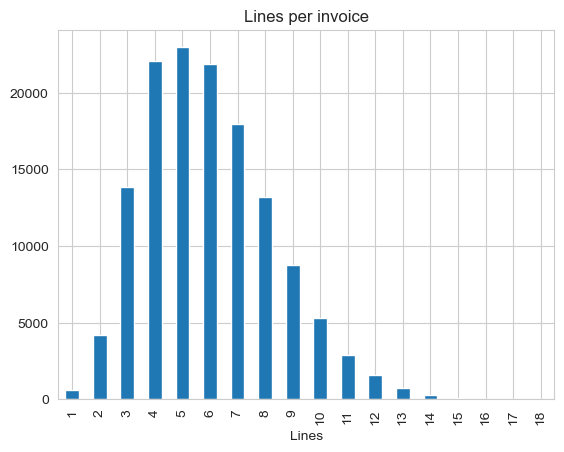

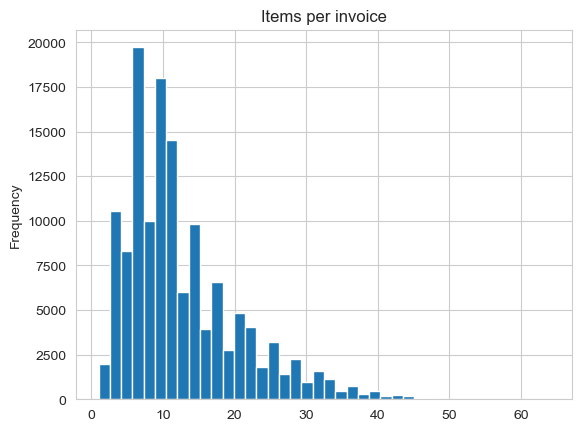

In [16]:
inv['Revenue'].plot.hist(bins=50, title='Invoice value')
plt.show()
inv['Lines'].value_counts().sort_index().plot.bar(title='Lines per invoice')
plt.show()
inv['Items'].plot.hist(bins=40, title='Items per invoice')
plt.show()

In [17]:
inv[['Revenue', 'Lines', 'Items']].describe()

,Revenue,Lines,Items
count,136452.000000,136452.000000,136452.000000
mean,550.697656,5.972276,12.664212
std,376.240045,2.346029,8.052017
min,5.170000,1.000000,1.000000
25%,277.982000,4.000000,7.000000
50%,456.017500,6.000000,10.000000
75%,728.593500,7.000000,16.000000
max,3644.420000,18.000000,64.000000


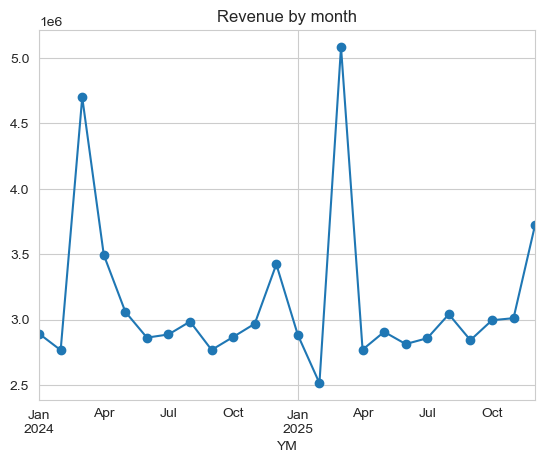

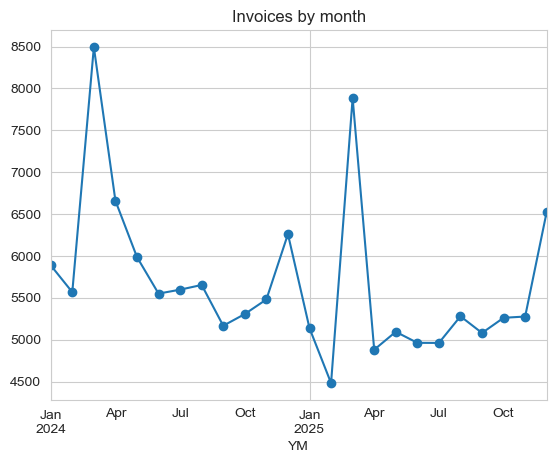

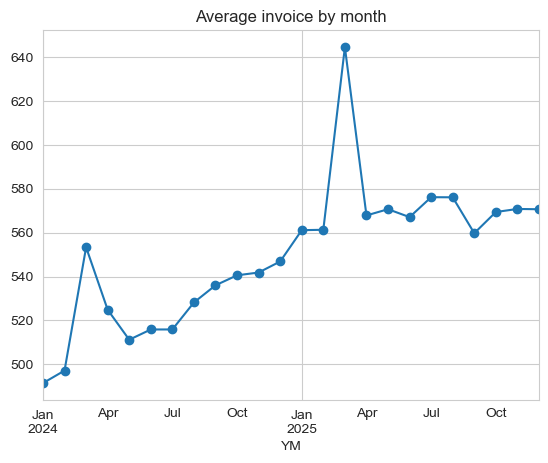

In [18]:
df.groupby('YM')['Revenue'].sum().plot(marker='o', title='Revenue by month')
plt.show()
inv.groupby('YM').size().plot(marker='o', title='Invoices by month')
plt.show()
inv.groupby('YM')['Revenue'].mean().plot(marker='o', title='Average invoice by month')
plt.show()

In [19]:
by_month = df.pivot_table(index='Month', columns='Year', values='Revenue', aggfunc='sum')
display(by_month)
by_month['Change %'] = (by_month[2025] / by_month[2024] - 1) * 100
by_month.round(1)

Year,2024,2025
Month,,
1,2.893777e+06,2.883189e+06
2,2.767889e+06,2.515886e+06
3,4.700194e+06,5.083670e+06
4,3.495537e+06,2.771771e+06
5,3.060438e+06,2.907793e+06
6,2.863506e+06,2.814561e+06
7,2.887818e+06,2.859060e+06
8,2.986319e+06,3.042039e+06
9,2.769536e+06,2.844160e+06


Year,2024,2025,Change %
Month,,,
1,2893777.1,2883189.3,-0.4
2,2767889.3,2515886.1,-9.1
3,4700194.0,5083669.8,8.2
4,3495537.4,2771771.3,-20.7
5,3060438.4,2907793.4,-5.0
6,2863506.3,2814560.7,-1.7
7,2887818.0,2859060.1,-1.0
8,2986319.2,3042038.7,1.9
9,2769536.4,2844160.2,2.7


In [20]:
display(df.groupby('Year')['Revenue'].sum())
display(inv.groupby(inv['Date'].dt.year).size())
df['List_Value'] = df['Quantity'] * df['List_Price']
df.groupby('Year')['List_Value'].sum()

Year
2024    3.768752e+07
2025    3.745627e+07
Name: Revenue, dtype: float64

Date
2024    71617
2025    64835
dtype: int64

Year
2024    37960576
2025    35668010
Name: List_Value, dtype: int64

In [21]:
order = ['Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
weekday_revenue = inv.groupby('Weekday')['Revenue'].sum().reindex(order)
display(weekday_revenue)
(weekday_revenue / weekday_revenue.sum() * 100).round(1)

Weekday
Saturday     1.560317e+07
Sunday       1.066538e+07
Monday       9.414414e+06
Tuesday      8.271214e+06
Wednesday    8.164323e+06
Thursday     9.193188e+06
Friday       1.383210e+07
Name: Revenue, dtype: float64

Weekday
Saturday     20.8
Sunday       14.2
Monday       12.5
Tuesday      11.0
Wednesday    10.9
Thursday     12.2
Friday       18.4
Name: Revenue, dtype: float64

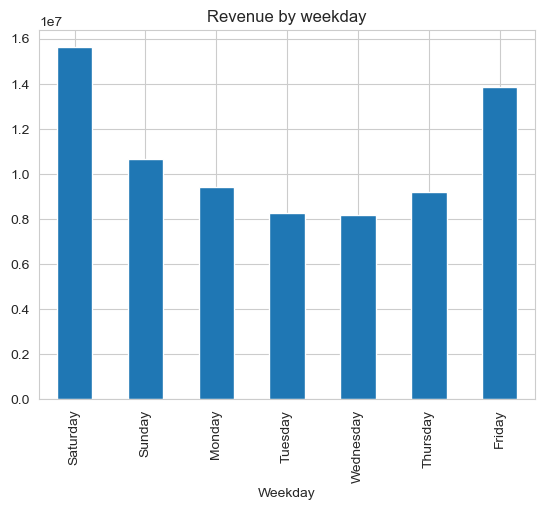

In [22]:
weekday_revenue.plot.bar(title='Revenue by weekday')
plt.show()

In [23]:
inv.groupby('Weekday')['Revenue'].mean().reindex(order).round(1)

Weekday
Saturday     554.2
Sunday       547.0
Monday       550.4
Tuesday      550.4
Wednesday    548.6
Thursday     556.6
Friday       547.5
Name: Revenue, dtype: float64

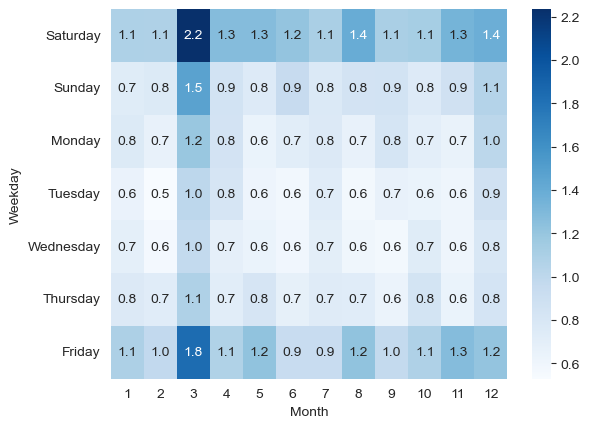

In [24]:
heat = df.pivot_table(index='Weekday', columns='Month', values='Revenue', aggfunc='sum')
heat = heat.reindex(order) / 1e6
sns.heatmap(heat, annot=True, fmt='.1f', cmap='Blues')
plt.show()

In [25]:
cat = df.groupby('Category')[['Revenue', 'Profit', 'Quantity']].sum()
cat = cat.sort_values('Revenue', ascending=False)
display(cat)
cat['Share %'] = cat['Revenue'] / cat['Revenue'].sum() * 100
cat['Margin %'] = cat['Profit'] / cat['Revenue'] * 100
cat.round(1)

,Revenue,Profit,Quantity
Category,,,
Eggs & Poultry,1.287518e+07,2.864637e+06,138368
Dairy,8.616858e+06,2.195288e+06,170688
Personal Care,6.861159e+06,1.989262e+06,117091
Oils & Sauces,6.796830e+06,1.755543e+06,147116
Beverages,6.569173e+06,1.742556e+06,159463
Grains & Pasta,5.552762e+06,1.499402e+06,171701
Household,4.629174e+06,1.401497e+06,121037
Frozen,4.580215e+06,1.308094e+06,75994
Baby & Kids,4.398951e+06,1.073529e+06,44902


,Revenue,Profit,Quantity,Share %,Margin %
Category,,,,,
Eggs & Poultry,12875181.9,2864636.9,138368,17.1,22.2
Dairy,8616858.4,2195288.2,170688,11.5,25.5
Personal Care,6861158.6,1989262.4,117091,9.1,29.0
Oils & Sauces,6796830.3,1755543.3,147116,9.0,25.8
Beverages,6569173.4,1742556.0,159463,8.7,26.5
Grains & Pasta,5552762.4,1499402.4,171701,7.4,27.0
Household,4629174.3,1401497.3,121037,6.2,30.3
Frozen,4580215.1,1308094.1,75994,6.1,28.6
Baby & Kids,4398951.4,1073529.4,44902,5.9,24.4


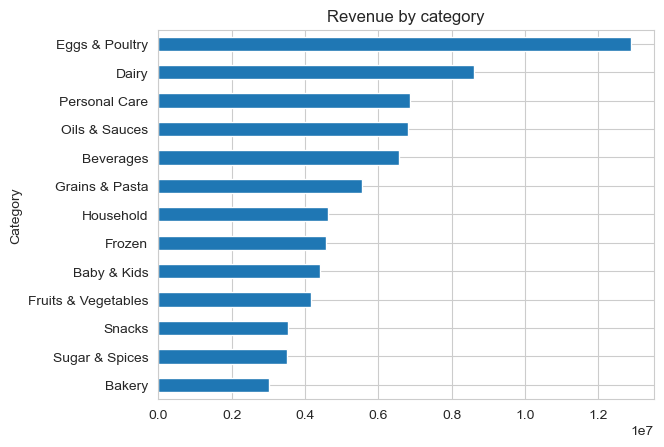

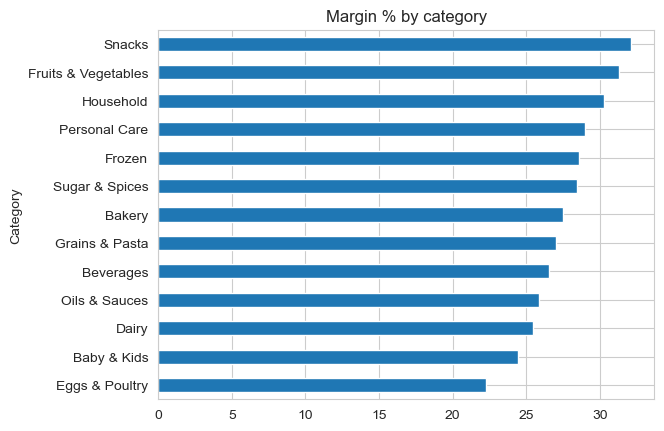

In [26]:
cat['Revenue'].sort_values().plot.barh(title='Revenue by category')
plt.show()
cat['Margin %'].sort_values().plot.barh(title='Margin % by category')
plt.show()

In [27]:
products = df.groupby('Product_Name')[['Revenue', 'Quantity', 'Profit']].sum()
products = products.sort_values('Revenue', ascending=False)
products.head(10).round(0)

,Revenue,Quantity,Profit
Product_Name,,,
Chicken 1kg,3127110.0,32243,612156.0
Coffee 200g,2503281.0,25001,628206.0
Eggs 12pc,2335274.0,32659,539029.0
Cooking Oil 1L,2100245.0,28614,440633.0
Diapers Pack,2004636.0,10370,449136.0
Cheddar Cheese Slices,1709827.0,17622,441043.0
Milk 1L,1592913.0,48788,422001.0
Frozen Pizza,1591543.0,17347,411947.0
Ice Cream Tub,1518014.0,17484,434006.0


In [28]:
display(products.tail(10).round(0))
products[products['Profit'] < 0].round(0)

,Revenue,Quantity,Profit
Product_Name,,,
Soda Can 330ml,125671.0,10236,-21728.0
Cumin 50g,125356.0,10223,43572.0
Yogurt 170g,125281.0,10223,43497.0
Spice Mix,124949.0,10188,43445.0
Wafer Pack,103263.0,10100,42663.0
Water 1.5L,84516.0,10367,32681.0
Chips Small,84161.0,10311,32606.0
Vanilla 10g,83958.0,10304,32438.0
Salt 700g,83710.0,10247,32475.0


,Revenue,Quantity,Profit
Product_Name,,,
Cake Slice,263683.0,10333,-46307.0
Milk 500ml,182243.0,9887,-31316.0
Soda Can 330ml,125671.0,10236,-21728.0


In [29]:
products['Cum Share'] = products['Revenue'].cumsum() / products['Revenue'].sum()
print((products['Cum Share'] <= 0.5).sum() + 1, 'products make 50% of revenue')
print((products['Cum Share'] <= 0.8).sum() + 1, 'products make 80% of revenue')

27 products make 50% of revenue
66 products make 80% of revenue


In [30]:
df.groupby('Is_Perishable')[['Revenue', 'Profit']].sum()

,Revenue,Profit
Is_Perishable,,
False,4.187059e+07,1.159812e+07
True,3.327321e+07,8.504422e+06


In [31]:
store_info = stores.rename(columns={'Store_Name': 'Store'})[['Store', 'Region', 'Size_Class']]
inv = inv.merge(store_info, on='Store', how='left')

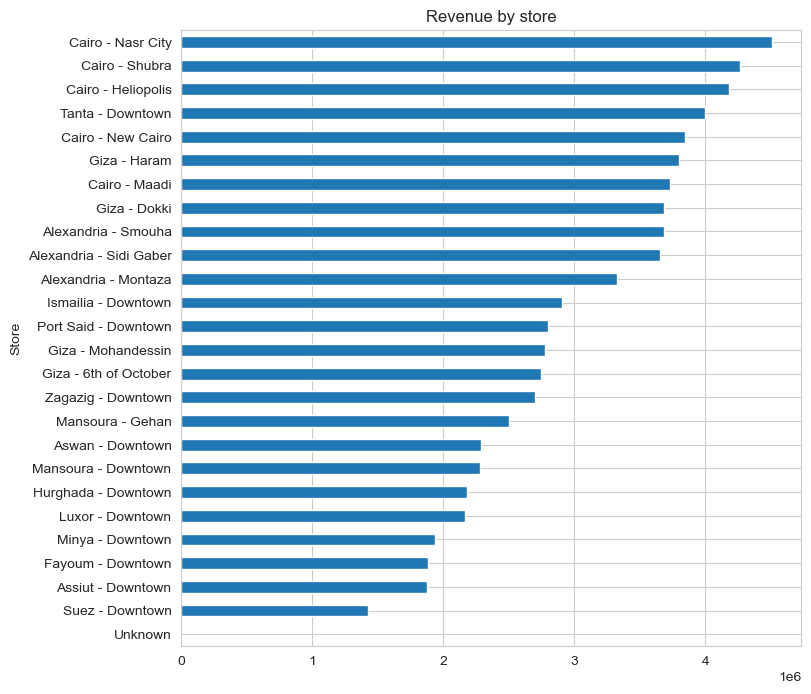

In [32]:
store_revenue = inv.groupby('Store')['Revenue'].sum().sort_values()
store_revenue.plot.barh(figsize=(8, 8), title='Revenue by store')
plt.show()

In [33]:
display(inv.groupby('Store')['Revenue'].mean().sort_values().round(0))
display(inv.groupby('Size_Class')['Revenue'].sum())
inv.groupby('Region')['Revenue'].sum()

Store
Unknown                     70.0
Assiut - Downtown          475.0
Port Said - Downtown       512.0
Suez - Downtown            515.0
Fayoum - Downtown          527.0
Cairo - Maadi              529.0
Giza - 6th of October      532.0
Cairo - New Cairo          535.0
Giza - Mohandessin         535.0
Alexandria - Smouha        540.0
Tanta - Downtown           543.0
Minya - Downtown           548.0
Mansoura - Downtown        554.0
Luxor - Downtown           558.0
Alexandria - Montaza       558.0
Alexandria - Sidi Gaber    558.0
Cairo - Heliopolis         560.0
Hurghada - Downtown        560.0
Mansoura - Gehan           562.0
Aswan - Downtown           562.0
Cairo - Nasr City          564.0
Cairo - Shubra             565.0
Zagazig - Downtown         574.0
Ismailia - Downtown        578.0
Giza - Dokki               584.0
Giza - Haram               596.0
Name: Revenue, dtype: float64

Size_Class
Large     2.128868e+07
Medium    3.386995e+07
Small     1.998502e+07
Name: Revenue, dtype: float64

Region
Alexandria       1.066160e+07
Canal            7.135929e+06
Delta            1.148344e+07
Greater Cairo    3.354092e+07
Red Sea          2.177451e+06
Upper Egypt      1.014432e+07
Name: Revenue, dtype: float64

In [34]:
store_table = inv.groupby('Store')['Revenue'].sum().reset_index()
store_table = store_table.merge(store_info, on='Store')
display(store_table.groupby('Size_Class')['Revenue'].mean().round(0))
store_table.groupby('Region')['Revenue'].mean().round(0)

Size_Class
Large     3548114.0
Medium    3386995.0
Small     2220558.0
Name: Revenue, dtype: float64

Region
Alexandria       3553866.0
Canal            2378643.0
Delta            2870860.0
Greater Cairo    3726769.0
Red Sea          2177451.0
Upper Egypt      2028864.0
Name: Revenue, dtype: float64

In [35]:
print(inv['Channel'].value_counts())
print(inv['Channel'].value_counts(normalize=True).round(3))
inv.groupby('Channel')[['Revenue', 'Items', 'Lines']].mean().round(1)

Channel
In-Store         115887
Delivery          13778
Online Pickup      6787
Name: count, dtype: int64
Channel
In-Store         0.849
Delivery         0.101
Online Pickup    0.050
Name: proportion, dtype: float64


,Revenue,Items,Lines
Channel,,,
Delivery,548.9,12.7,6.0
In-Store,551.1,12.7,6.0
Online Pickup,548.2,12.6,5.9


In [36]:
print(inv['Payment_Method'].value_counts())
print(inv['Payment_Method'].value_counts(normalize=True).round(3))
inv.groupby('Payment_Method')['Revenue'].mean().round(1)

Payment_Method
Cash             69594
Credit Card      41459
Mobile Wallet    25399
Name: count, dtype: int64
Payment_Method
Cash             0.510
Credit Card      0.304
Mobile Wallet    0.186
Name: proportion, dtype: float64


Payment_Method
Cash             554.9
Credit Card      541.0
Mobile Wallet    554.9
Name: Revenue, dtype: float64

In [37]:
pd.crosstab(inv['Channel'], inv['Payment_Method'], normalize='index').round(3)

Payment_Method,Cash,Credit Card,Mobile Wallet
Channel,,,
Delivery,0.505,0.312,0.183
In-Store,0.511,0.303,0.187
Online Pickup,0.505,0.310,0.185


In [38]:
df['Has Discount'] = df['Discount'] > 0
print(df['Has Discount'].mean())
df['Discount'].value_counts().sort_index()

0.20303241141252795


Discount
0.000    649472
0.015       139
0.020       136
0.050     26874
0.100     30300
0.150     27037
0.200     27016
0.250     27147
0.300     26808
Name: count, dtype: int64

In [39]:
display(df.groupby('Has Discount')['Quantity'].mean())
df.groupby('Discount')['Quantity'].mean()

Has Discount
False    2.148541
True     2.010432
Name: Quantity, dtype: float64

Discount
0.000    2.148541
0.015    1.935252
0.020    2.051471
0.050    1.995795
0.100    2.017624
0.150    2.007656
0.200    2.013807
0.250    2.012046
0.300    2.014921
Name: Quantity, dtype: float64

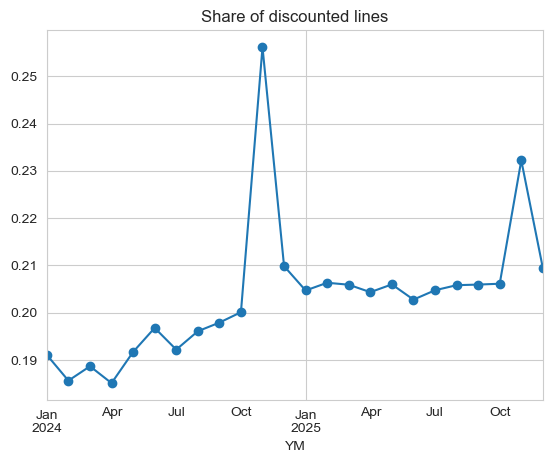

In [40]:
df.groupby('YM')['Has Discount'].mean().plot(marker='o', title='Share of discounted lines')
plt.show()

In [41]:
with_cust = df.merge(cust[['Customer_ID', 'Loyalty_Member']], on='Customer_ID')
by_loyalty = with_cust.groupby('Loyalty_Member')[['Discount_Amt', 'Gross']].sum()
by_loyalty['Discount %'] = by_loyalty['Discount_Amt'] / by_loyalty['Gross'] * 100
display(by_loyalty.round(2))
by_cat = df.groupby('Category')[['Discount_Amt', 'Gross']].sum()
(by_cat['Discount_Amt'] / by_cat['Gross'] * 100).round(2)

,Discount_Amt,Gross,Discount %
Loyalty_Member,,,
No,985455.27,23310265.96,4.23
Yes,1620443.03,54438216.15,2.98


Category
Baby & Kids            3.55
Bakery                 3.35
Beverages              3.38
Dairy                  3.31
Eggs & Poultry         3.33
Frozen                 3.36
Fruits & Vegetables    3.29
Grains & Pasta         3.35
Household              3.39
Oils & Sauces          3.37
Personal Care          3.27
Snacks                 3.39
Sugar & Spices         3.28
dtype: float64

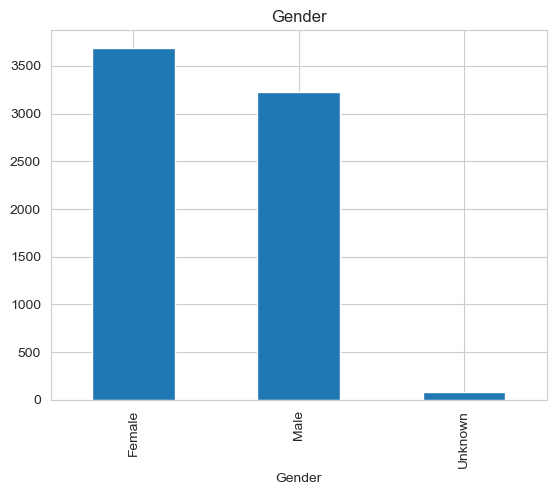

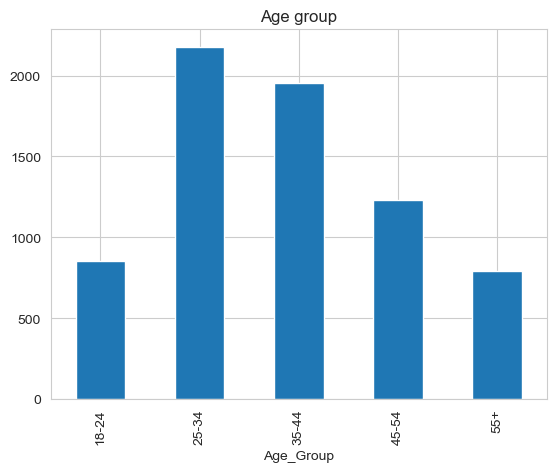

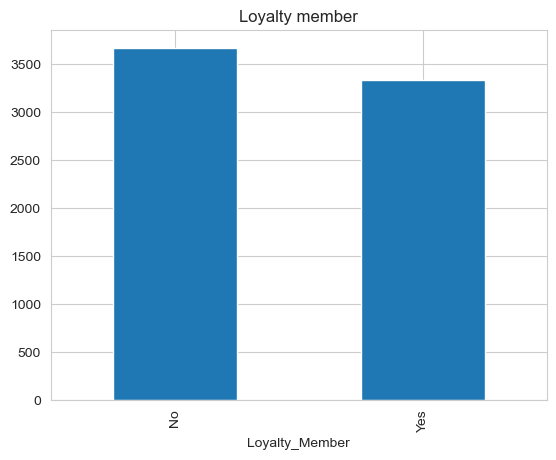

In [42]:
cust['Gender'].value_counts().plot.bar(title='Gender')
plt.show()
cust['Age_Group'].value_counts().sort_index().plot.bar(title='Age group')
plt.show()
cust['Loyalty_Member'].value_counts().plot.bar(title='Loyalty member')
plt.show()

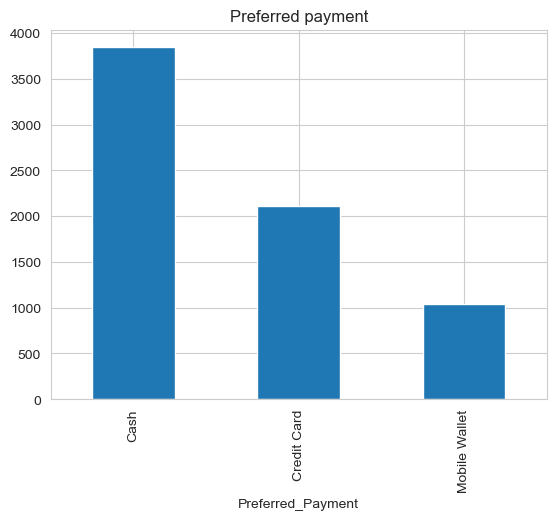

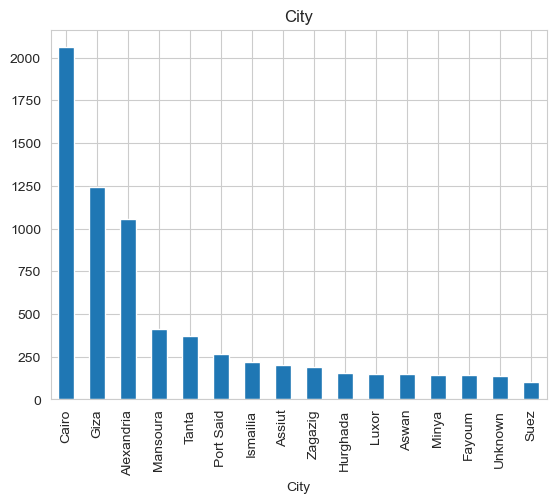

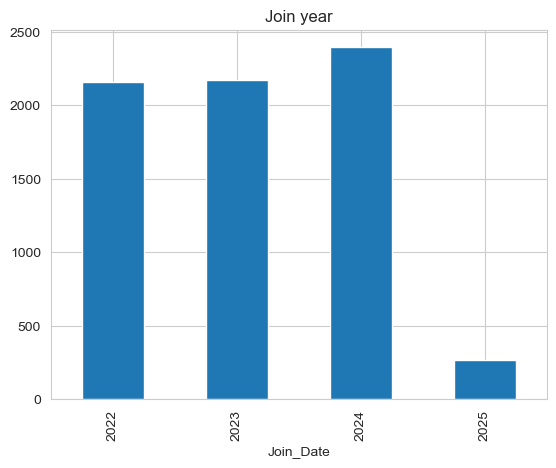

In [43]:
cust['Preferred_Payment'].value_counts().plot.bar(title='Preferred payment')
plt.show()
cust['City'].value_counts().plot.bar(title='City')
plt.show()
cust['Join_Date'].dt.year.value_counts().sort_index().plot.bar(title='Join year')
plt.show()

In [44]:
cust['Birth_Year'].describe()

count    7000.000000
mean     1981.370714
std        17.089007
min      1850.000000
25%      1968.000000
50%      1982.000000
75%      1995.000000
max      2030.000000
Name: Birth_Year, dtype: float64

In [45]:
cust['Age'] = 2025 - cust['Birth_Year']
display(cust[(cust['Age'] < 16) | (cust['Age'] > 90)].shape[0])
cust['Age_Check'] = pd.cut(cust['Age'], [0, 17, 24, 34, 44, 54, 200], labels=['Under18', '18-24', '25-34', '35-44', '45-54', '55+']).astype(str)
(cust['Age_Check'] != cust['Age_Group']).sum()

42

np.int64(5640)

In [46]:
cust.groupby('Age_Group')['Age'].median()

Age_Group
18-24    43.0
25-34    43.0
35-44    43.0
45-54    43.0
55+      45.0
Name: Age, dtype: float64

In [47]:
known = inv[inv['Customer_ID'].isin(cust['Customer_ID'])]
last_day = df['Date'].max() + pd.Timedelta(days=1)

In [48]:
rfm = pd.DataFrame()
rfm['Frequency'] = known.groupby('Customer_ID').size()
rfm['Monetary'] = known.groupby('Customer_ID')['Revenue'].sum()
rfm['AvgInvoice'] = known.groupby('Customer_ID')['Revenue'].mean()

In [49]:
rfm['AvgItems'] = known.groupby('Customer_ID')['Items'].mean()
rfm['AvgLines'] = known.groupby('Customer_ID')['Lines'].mean()
rfm['AvgUniqueSKUs'] = known.groupby('Customer_ID')['Unique_SKUs'].mean()
rfm['Recency'] = (last_day - known.groupby('Customer_ID')['Date'].max()).dt.days

In [50]:
known = known.sort_values(['Customer_ID', 'Date'])
gaps = known.groupby('Customer_ID')['Date'].diff().dt.days
rfm['AvgPurchaseGap'] = gaps.groupby(known['Customer_ID']).mean()
cust_disc = df[df['Customer_ID'].isin(cust['Customer_ID'])].groupby('Customer_ID')[['Discount_Amt', 'Gross']].sum()
rfm['DiscountPct'] = cust_disc['Discount_Amt'] / cust_disc['Gross']

In [51]:
rfm.describe().round(1)

,Frequency,Monetary,AvgInvoice,AvgItems,AvgLines,AvgUniqueSKUs,Recency,AvgPurchaseGap,DiscountPct
count,7000.0,7000.0,7000.0,7000.0,7000.0,7000.0,7000.0,6896.0,7000.0
mean,19.5,10734.7,435.4,9.8,5.4,5.3,118.6,50.0,0.0
std,16.3,14564.9,177.4,4.2,1.1,1.0,175.2,50.6,0.0
min,1.0,62.8,62.8,2.0,2.0,2.0,1.0,5.8,0.0
25%,8.0,2725.2,334.8,7.5,4.6,4.6,12.0,22.5,0.0
50%,13.0,5072.9,395.2,8.8,5.4,5.4,32.0,33.2,0.0
75%,26.0,11306.6,454.6,10.0,6.0,6.0,123.0,62.0,0.0
max,100.0,88618.8,1312.2,24.1,11.0,11.0,726.0,709.0,0.2


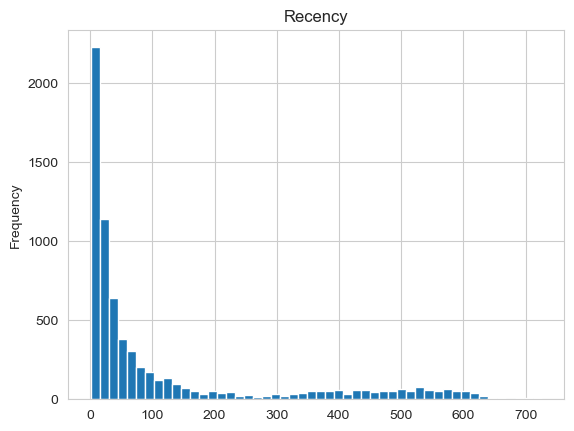

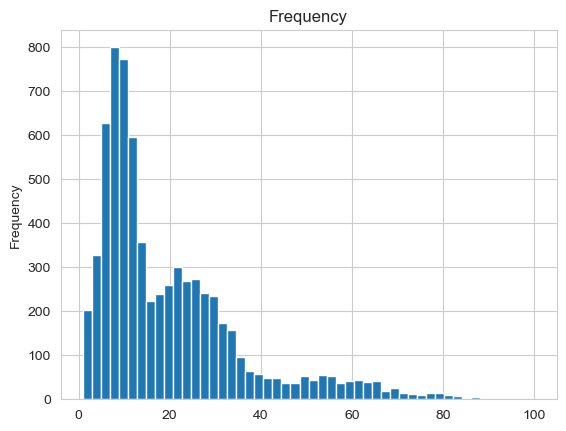

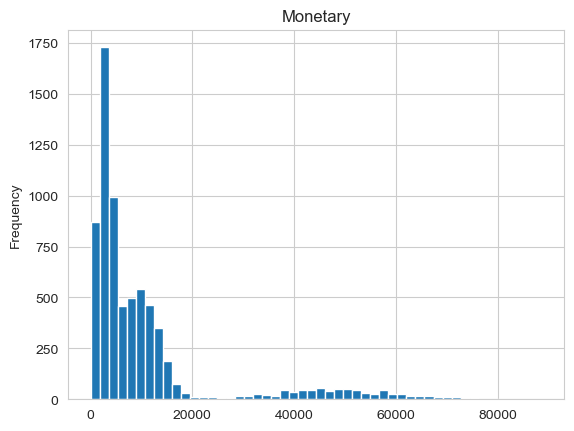

In [52]:
rfm['Recency'].plot.hist(bins=50, title='Recency')
plt.show()
rfm['Frequency'].plot.hist(bins=50, title='Frequency')
plt.show()
rfm['Monetary'].plot.hist(bins=50, title='Monetary')
plt.show()

In [53]:
rfm[['Recency', 'Frequency', 'Monetary']].skew().round(2)

Recency      1.68
Frequency    1.58
Monetary     2.44
dtype: float64

In [54]:
features = ['Recency', 'Frequency', 'Monetary', 'AvgInvoice', 'AvgItems', 'AvgLines', 'AvgUniqueSKUs', 'AvgPurchaseGap', 'DiscountPct']
rfm[features].skew().round(2)

Recency           1.68
Frequency         1.58
Monetary          2.44
AvgInvoice        1.65
AvgItems          1.84
AvgLines          0.13
AvgUniqueSKUs     0.13
AvgPurchaseGap    4.25
DiscountPct       2.10
dtype: float64

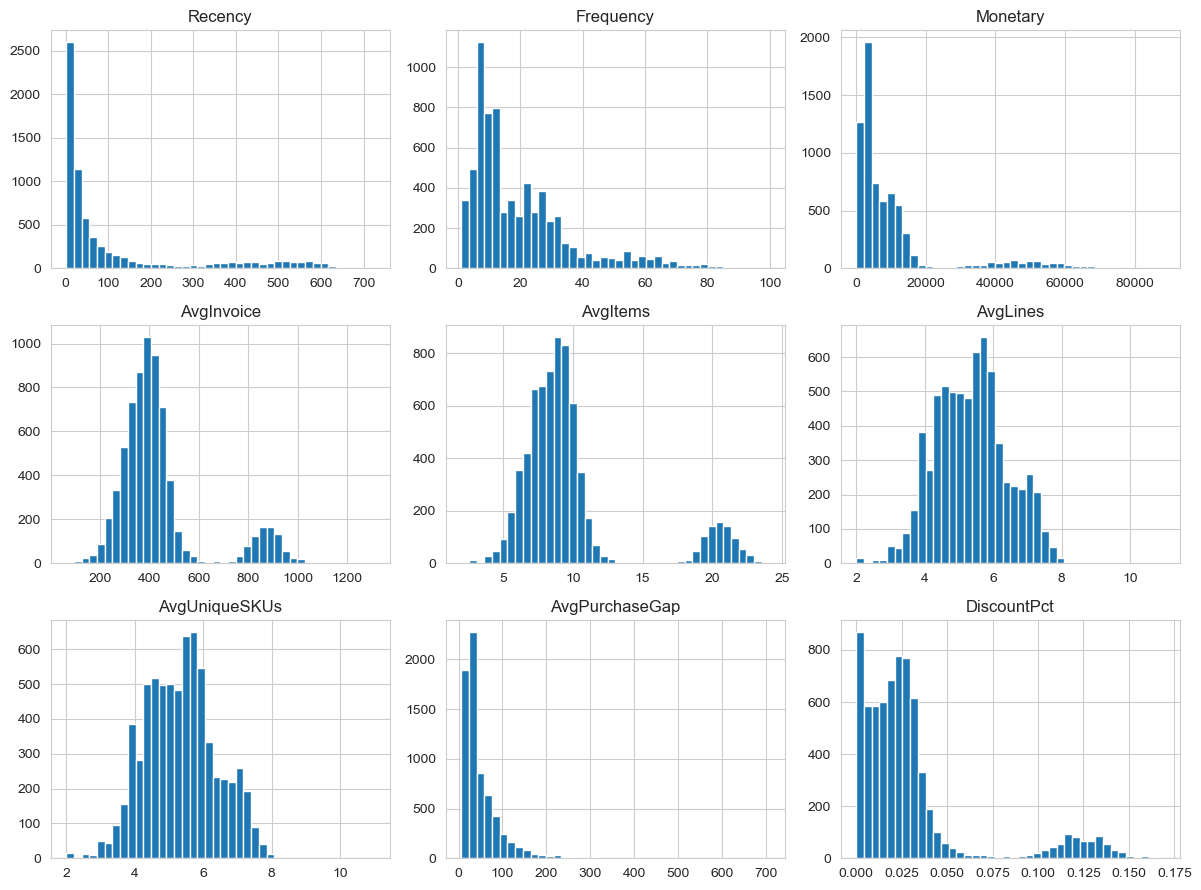

In [55]:
rfm[features].hist(bins=40, figsize=(12, 9))
plt.tight_layout()
plt.show()

In [56]:
q1 = rfm[features].quantile(0.25)
q3 = rfm[features].quantile(0.75)
iqr = q3 - q1
outliers = (rfm[features] < q1 - 1.5 * iqr) | (rfm[features] > q3 + 1.5 * iqr)
(outliers.mean() * 100).round(1)

Recency           17.1
Frequency          6.0
Monetary          11.1
AvgInvoice        12.5
AvgItems          12.0
AvgLines           0.3
AvgUniqueSKUs      0.3
AvgPurchaseGap     6.2
DiscountPct       10.8
dtype: float64

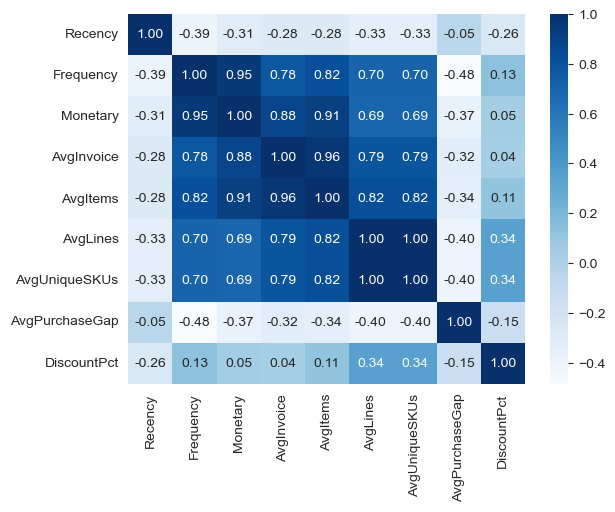

In [57]:
sns.heatmap(rfm[features].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

In [58]:
spend = rfm['Monetary'].sort_values(ascending=False)
n = len(spend)
print('top 10%:', round(spend.head(int(n * 0.1)).sum() / spend.sum(), 3))
print('top 20%:', round(spend.head(int(n * 0.2)).sum() / spend.sum(), 3))
print('bought once:', round((rfm['Frequency'] == 1).mean(), 3))
print('no purchase for 90 days:', round((rfm['Recency'] > 90).mean(), 3))
print('no purchase for 180 days:', round((rfm['Recency'] > 180).mean(), 3))

top 10%: 0.473
top 20%: 0.627
bought once: 0.015
no purchase for 90 days: 0.295
no purchase for 180 days: 0.205


In [59]:
gaps.describe().round(1)

count    129437.0
mean         28.9
std          40.6
min           0.0
25%           6.0
50%          16.0
75%          35.0
max         709.0
Name: Date, dtype: float64

In [60]:
customers = rfm.join(cust.set_index('Customer_ID'))

In [61]:
display(customers.groupby('Loyalty_Member')[['Recency', 'Frequency', 'Monetary', 'AvgInvoice']].mean().round(1))
display(customers.groupby('Age_Group')[['Recency', 'Frequency', 'Monetary', 'AvgInvoice']].mean().round(1))
customers.groupby('Gender')[['Recency', 'Frequency', 'Monetary', 'AvgInvoice']].mean().round(1)

,Recency,Frequency,Monetary,AvgInvoice
Loyalty_Member,,,,
No,159.5,13.2,6084.7,384.9
Yes,73.5,26.4,15856.4,490.9


,Recency,Frequency,Monetary,AvgInvoice
Age_Group,,,,
18-24,114.5,19.1,10115.7,426.3
25-34,116.7,19.6,10806.7,437.6
35-44,119.1,19.7,11089.6,441.4
45-54,126.2,19.3,10696.4,432.7
55+,115.1,19.3,10387.7,428.3


,Recency,Frequency,Monetary,AvgInvoice
Gender,,,,
Female,122.6,19.3,10524.6,433.0
Male,114.1,19.7,10947.7,437.6
Unknown,117.9,19.9,11777.7,454.3


In [62]:
paid = known.merge(cust[['Customer_ID', 'Preferred_Payment']], on='Customer_ID')
(paid['Payment_Method'] == paid['Preferred_Payment']).mean()

np.float64(0.865630290903494)

In [63]:
trips = known.merge(stores[['Store_Name', 'City']], left_on='Store', right_on='Store_Name')
trips = trips.merge(cust[['Customer_ID', 'City']], on='Customer_ID', suffixes=('_store', '_customer'))
display((trips['City_store'] == trips['City_customer']).mean())
trips.groupby('Customer_ID')['Store'].nunique().describe().round(1)

np.float64(0.8688313116135888)

count    7000.0
mean        3.1
std         2.0
min         1.0
25%         2.0
50%         3.0
75%         4.0
max        13.0
Name: Store, dtype: float64

In [64]:
items = df[['Transaction_ID', 'Product_ID']].drop_duplicates()
n_invoices = items['Transaction_ID'].nunique()

In [65]:
names = prod.set_index('Product_ID')['Product_Name']
product_share = items['Product_ID'].value_counts() / n_invoices
display(product_share.head(10).rename(index=names).round(3))
product_share.tail(3).rename(index=names).round(3)

Product_ID
Milk 1L              0.168
Baladi Bread Pack    0.136
Rice 1kg             0.123
Eggs 12pc            0.112
Chicken 1kg          0.111
Sugar 1kg            0.104
Cooking Oil 1L       0.098
Soda 1L              0.096
Onions 1kg           0.093
Pasta 400g           0.085
Name: count, dtype: float64

Product_ID
Lemons 500g      0.033
Couscous 500g    0.033
Milk 500ml       0.033
Name: count, dtype: float64

In [66]:
pairs = items.merge(items, on='Transaction_ID')
pairs = pairs[pairs['Product_ID_x'] < pairs['Product_ID_y']]

In [67]:
pair_count = pairs.groupby(['Product_ID_x', 'Product_ID_y']).size().reset_index(name='Count')
pair_count = pair_count[pair_count['Count'] >= 100].copy()

In [68]:
pair_count['Support'] = pair_count['Count'] / n_invoices
pair_count['Support_x'] = pair_count['Product_ID_x'].map(product_share)
pair_count['Support_y'] = pair_count['Product_ID_y'].map(product_share)

In [69]:
pair_count['Conf_x_to_y'] = pair_count['Support'] / pair_count['Support_x']
pair_count['Conf_y_to_x'] = pair_count['Support'] / pair_count['Support_y']
pair_count['Lift'] = pair_count['Support'] / (pair_count['Support_x'] * pair_count['Support_y'])

In [70]:
pair_count['Product_x'] = pair_count['Product_ID_x'].map(names)
pair_count['Product_y'] = pair_count['Product_ID_y'].map(names)

In [71]:
top_pairs = pair_count.sort_values('Lift', ascending=False)
top_pairs[['Product_x', 'Product_y', 'Count', 'Support', 'Conf_x_to_y', 'Conf_y_to_x', 'Lift']].head(15).round(3)

,Product_x,Product_y,Count,Support,Conf_x_to_y,Conf_y_to_x,Lift
8773,Diapers Pack,Baby Wipes,4076,0.030,0.495,0.481,7.981
3839,Pasta 400g,Tomato Sauce 360g,6695,0.049,0.578,0.606,7.149
8348,Shampoo 400ml,Hair Conditioner 400ml,3171,0.023,0.396,0.414,7.061
7961,Dish Soap 750ml,Sponges 3pk,2629,0.019,0.330,0.370,6.327
2790,Chicken 1kg,Rice 1kg,10899,0.080,0.720,0.648,5.840
5786,Soda 1L,Chips Large,6291,0.046,0.478,0.545,5.658
7294,Tomatoes 1kg,Onions 1kg,5756,0.042,0.509,0.453,5.462
1526,Baladi Bread Pack,Eggs 12pc,11133,0.082,0.598,0.728,5.334
7001,Cookies Box,Ice Cream Tub,2015,0.015,0.313,0.251,5.313
783,Butter 200g,Toast Bread,2933,0.021,0.400,0.277,5.157


In [72]:
pair_count['Lift'].describe().round(3)

count    8778.000
mean        1.030
std         0.238
min         0.367
25%         0.969
50%         1.032
75%         1.095
max         7.981
Name: Lift, dtype: float64

In [73]:
print((pair_count['Lift'] >= 2).sum(), 'pairs with lift 2 or more')
print(len(pair_count), 'pairs in total')
print((pair_count['Support'] >= 0.005).sum(), 'pairs with support 0.5% or more')

20 pairs with lift 2 or more
8778 pairs in total
144 pairs with support 0.5% or more


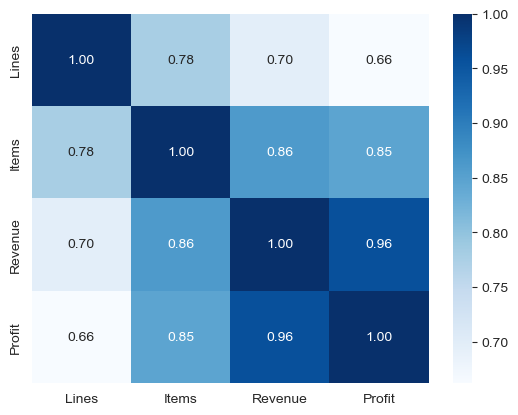

In [74]:
sns.heatmap(inv[['Lines', 'Items', 'Revenue', 'Profit']].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

In [75]:
inv.sort_values('Revenue', ascending=False).head(10)[['Transaction_ID', 'Date', 'Store', 'Channel', 'Lines', 'Items', 'Revenue']].round(0)

,Transaction_ID,Date,Store,Channel,Lines,Items,Revenue
83881,T083887,2025-03-11,Fayoum - Downtown,In-Store,14,62,3644.0
50907,T050912,2024-09-09,Cairo - Maadi,In-Store,13,64,3362.0
62782,T062787,2024-11-17,Alexandria - Sidi Gaber,Delivery,9,38,3151.0
97947,T097953,2025-05-24,Giza - Dokki,Delivery,13,46,3119.0
55580,T055585,2024-10-06,Cairo - Nasr City,In-Store,15,62,3081.0
94462,T094468,2025-05-03,Giza - 6th of October,In-Store,15,53,3068.0
52167,T052172,2024-09-17,Alexandria - Montaza,In-Store,14,55,3047.0
126096,T126104,2025-11-09,Giza - Mohandessin,In-Store,12,44,3016.0
85577,T085583,2025-03-17,Aswan - Downtown,In-Store,9,42,2968.0
121451,T121459,2025-10-12,Cairo - Nasr City,Online Pickup,17,53,2962.0


In [76]:
rfm.to_csv('customer_features_rfm.csv')
print(rfm.shape)

(7000, 9)


In [77]:
from sklearn.preprocessing import StandardScaler

selected = ['Recency', 'Frequency', 'Monetary', 'AvgInvoice']
rfm_log = np.log1p(rfm[selected])
rfm_log.skew().round(2)

Recency       0.18
Frequency    -0.08
Monetary      0.07
AvgInvoice    0.47
dtype: float64

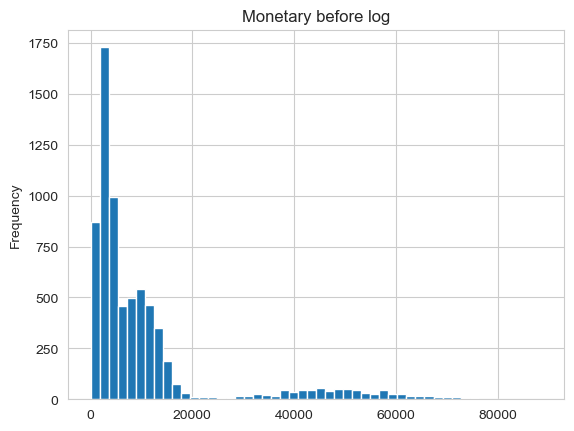

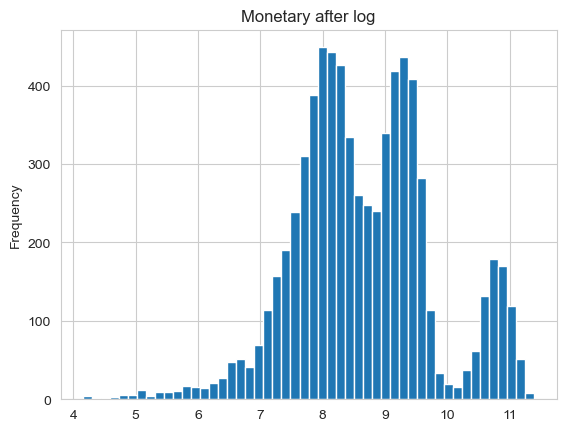

In [78]:
rfm['Monetary'].plot.hist(bins=50, title='Monetary before log')
plt.show()
rfm_log['Monetary'].plot.hist(bins=50, title='Monetary after log')
plt.show()

In [79]:
scaler = StandardScaler()
scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(scaled, index=rfm_log.index, columns=selected)

In [80]:
rfm_scaled.to_csv('customer_features_rfm_scaled.csv')
print(rfm_scaled.shape)

(7000, 4)


In [81]:
audit = pd.DataFrame({
 'Check': ['Rows before Join_Date', 'Customers with Join_Date issue', 'Age_Group vs Birth_Year mismatch', 'Impossible ages', 'Repeated invoice-product pairs', 'Unknown store rows', 'Cost above List price'],
 'Count': [len(before_join), before_join['Customer_ID'].nunique(), (cust['Age_Check'] != cust['Age_Group']).sum(), cust[(cust['Age'] < 16) | (cust['Age'] > 90)].shape[0], tx.duplicated(['Transaction_ID', 'Product_ID']).sum(), (~tx['Store'].isin(stores['Store_Name'])).sum(), (prod['Cost_Price'] > prod['List_Price']).sum()]
})
audit.to_csv('EDA_QA_Audit.csv', index=False)
audit

,Check,Count
0,Rows before Join_Date,76476
1,Customers with Join_Date issue,1900
2,Age_Group vs Birth_Year mismatch,5640
3,Impossible ages,42
4,Repeated invoice-product pairs,2439
5,Unknown store rows,2
6,Cost above List price,3
